In [7]:
import tqdm
import numpy as np
import quimb as qu

from PhaseEstimation.utils import fidelity
from PhaseEstimation.annni.dmrg import dmrg_annni
from PhaseEstimation.annni.hamiltonian import get_energy_psi
from PhaseEstimation.utils.study.plot import imgs

In [2]:
num_spins = 6
side = 6

ks, hs = np.linspace(0, 1, side), np.linspace(0, 2, side)

In [3]:
E_dmrg, E_true = np.zeros((side, side)), np.zeros((side, side))
PSI_dmrg, PSI_true = np.empty((side, side), dtype=object), np.empty((side, side), dtype=object)
fid = np.zeros((side, side))

In [4]:
progress = tqdm.tqdm(range(len(ks) * len(hs)))
for x, k in enumerate(ks):
    for y, h in enumerate(hs):
        E_true[x, y], PSI_true[x, y] = get_energy_psi(num_spins, k, h)
        E_dmrg[x, y], mps = dmrg_annni(num_spins, 16, k, h) 
        PSI_dmrg[x,y] = qu.tensor.tensor_1d.MatrixProductState(mps, shape="lpr").to_dense()
        
        fid[x, y] = fidelity(PSI_dmrg[x, y], PSI_true[x, y])
        
        progress.update(1)

100%|██████████| 36/36 [02:26<00:00,  4.16s/it]

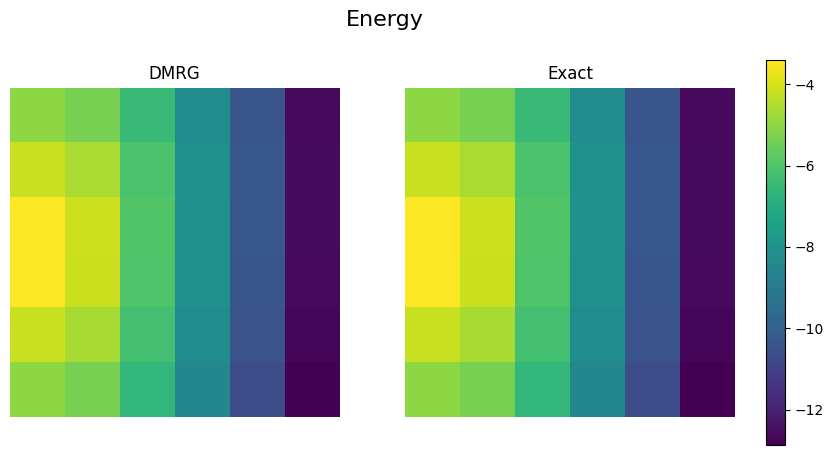

In [9]:
imgs([E_dmrg, E_true], ["DMRG", "Exact"], "Energy", cmap="viridis")

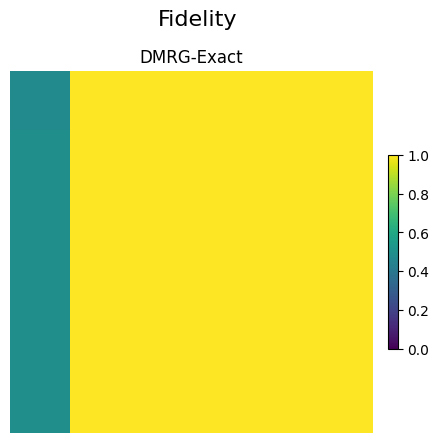

In [11]:
imgs([fid], ["DMRG-Exact"], "Fidelity", cmap="viridis", _range=(0, 1))
